
# Question 4: Topic Modelling Using LDA

## Introduction

This notebook addresses Question 4 of the NLP Project. The aim is to identify topics within the research article corpus using Latent Dirichlet Allocation (LDA).

The notebook will display the most important words associated with each topic, examine the distribution of topics across the documents, and use visualisations to interpret the results. An interactive intertopic distance map will also be created using pyLDAvis.

In [3]:

import pandas as pd
import glob
import os

# Locate the research article text files
article_files = sorted(glob.glob("research_corpus/research_*.txt"))

# Load the articles into a DataFrame
articles = []

for file in article_files:
    with open(file, "r", encoding="utf-8") as f:
        articles.append({
            "File": os.path.basename(file),
            "Article": f.read()})

df_articles = pd.DataFrame(articles)

# Check the loaded articles
print("Number of articles:", len(df_articles))
display(df_articles[["File"]])

Number of articles: 5


,File
0,research_1.txt
1,research_2.txt
2,research_3.txt
3,research_4.txt
4,research_5.txt


In [13]:

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer

# downloading  NLTK resources
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

# Set up text-processing tools
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

# Clean and preprocess each article
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    words = text.split()

    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words and len(word) > 2]

    return " ".join(words)

df_articles["Processed_Article"] = df_articles["Article"].apply(preprocess_text)

# Create a filtered document-term matrix
vectorizer = CountVectorizer(max_df=0.80,min_df=2)

dtm = vectorizer.fit_transform(df_articles["Processed_Article"])

print("Document-term matrix shape:", dtm.shape)
print("Number of documents:", dtm.shape[0])
print("Number of unique terms:", len(vectorizer.get_feature_names_out()))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\xikon\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\xikon\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\xikon\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Document-term matrix shape: (5, 781)
Number of documents: 5
Number of unique terms: 781


In [14]:
from sklearn.decomposition import LatentDirichletAllocation

# Set the number of topics
n_topics = 3

# Train LDA using the updated document-term matrix
lda_model = LatentDirichletAllocation(n_components=n_topics,random_state=42,max_iter=20,learning_method="batch")

lda_model.fit(dtm)
print("LDA model trained successfully.")
print("Number of topics:", lda_model.n_components)

LDA model trained successfully.
Number of topics: 3


In [16]:
# Get the updated vocabulary
feature_names = vectorizer.get_feature_names_out()

# Display the top 10 words for each topic
n_top_words = 10

for topic_idx, topic in enumerate(lda_model.components_):
    top_word_indices = topic.argsort()[-n_top_words:][::-1]
    top_words = [feature_names[i] for i in top_word_indices]

    print(f"\nTopic {topic_idx + 1}:")
    print(", ".join(top_words))


Topic 1:
alpha, triangulation, instrument, cronbach, reliability, science, item, student, author, education

Topic 2:
development, design, evaluation, model, product, orientation, term, system, specific, even

Topic 3:
method, mixed, quantitative, design, paradigm, multiple, reality, position, important, approach


In [19]:
# Calculate topic probabilities using the updated LDA model
topic_distribution = lda_model.transform(dtm)

topic_columns = [f"Topic {i + 1}" for i in range(n_topics)]

df_topic_distribution = pd.DataFrame(topic_distribution * 100,columns=topic_columns)

df_topic_distribution.insert(0, "Article", df_articles["File"])
df_topic_distribution[topic_columns] = (df_topic_distribution[topic_columns].round(2))
display(df_topic_distribution)

,Article,Topic 1,Topic 2,Topic 3
0,research_1.txt,0.02,0.02,99.96
1,research_2.txt,62.80,13.17,24.03
2,research_3.txt,0.03,99.93,0.03
3,research_4.txt,99.96,0.02,0.02
4,research_5.txt,55.52,0.03,44.45


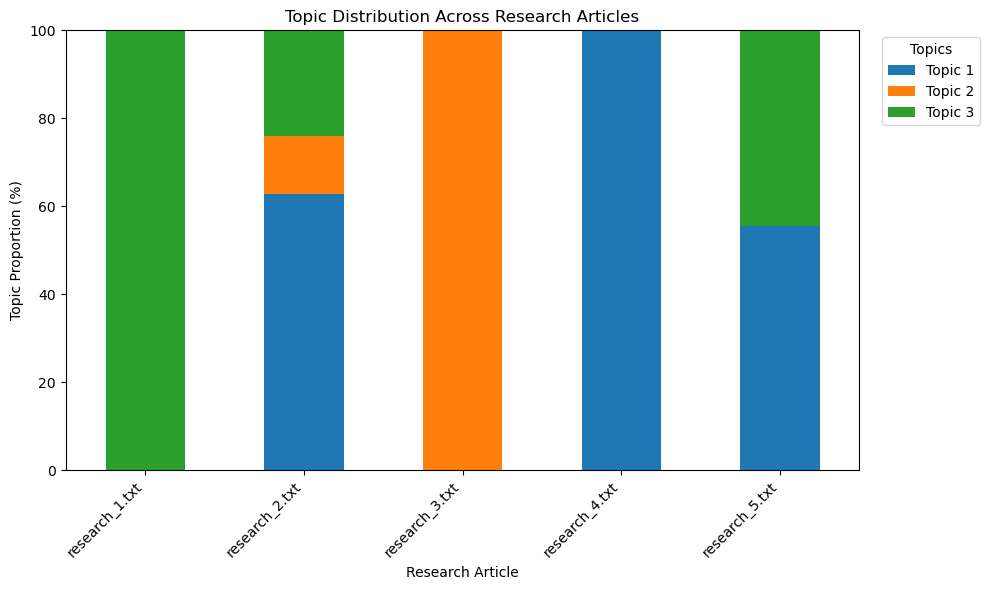

In [20]:
import matplotlib.pyplot as plt

# Prepare the updated topic distribution data
plot_data = df_topic_distribution.set_index("Article")

# Plot topic proportions for each article
plot_data.plot(kind="bar",stacked=True,figsize=(10, 6))

plt.title("Topic Distribution Across Research Articles")
plt.xlabel("Research Article")
plt.ylabel("Topic Proportion (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)
plt.legend(title="Topics", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Interpretation of Results

- Research 1 is mainly associated with Topic 3 (99.96%).
- Research 2 has a higher proportion of Topic 1 (62.80%), with Topic 3 accounting for 24.03% and Topic 2 for 13.17%.
- Research 3 is mostly associated with Topic 2 (99.93%).
- Research 4 is almost entirely associated with Topic 1 (99.96%).
- Research 5 contains a mixture of Topic 1 (55.52%) and Topic 3 (44.45%).

Overall, the articles show different topic distributions. While some are strongly linked to one topic, others contain a mix of topics. The top words for each topic can help explain what these topics represent. Since the analysis uses only five articles, the results should be interpreted with caution.

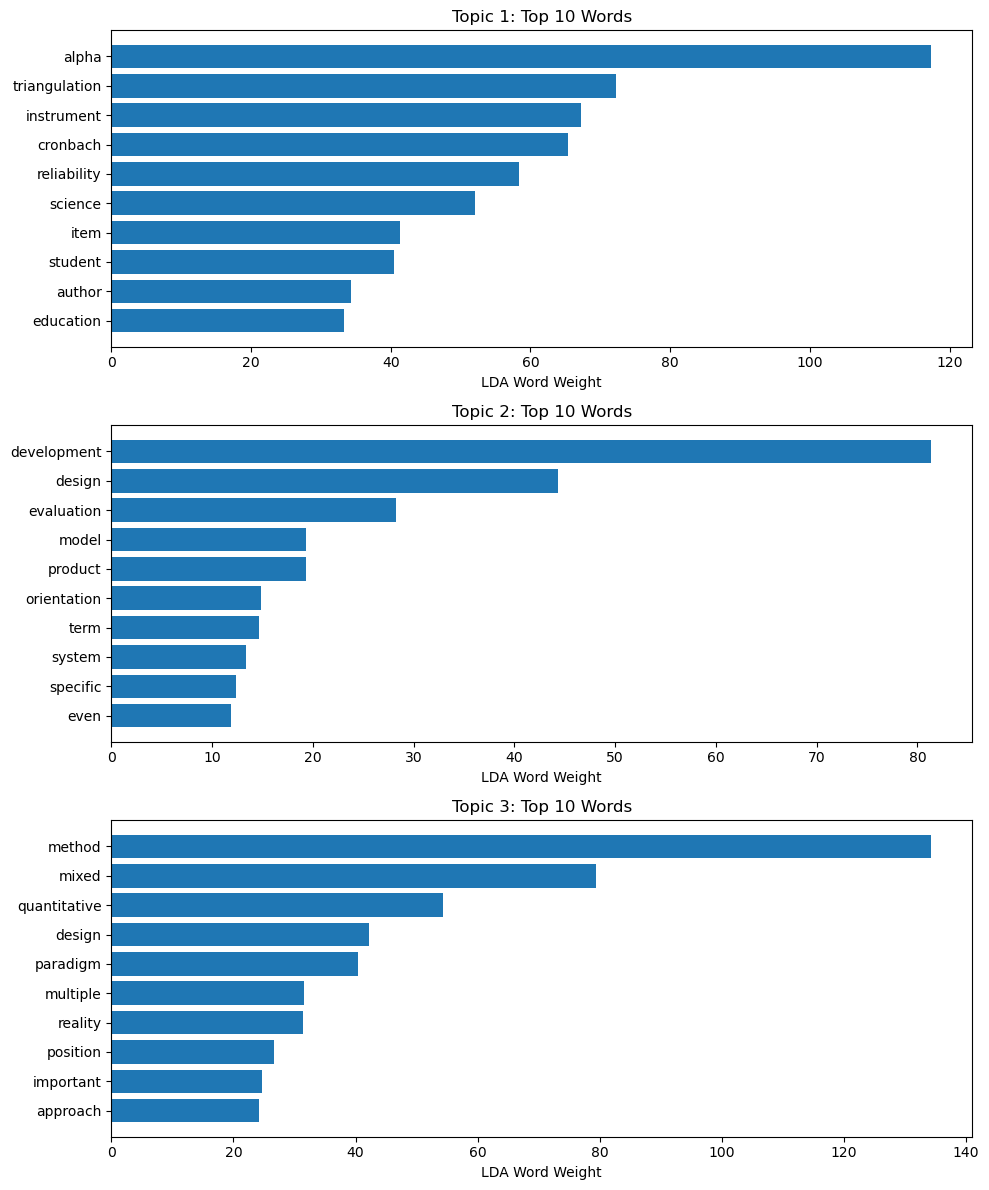

In [22]:
import matplotlib.pyplot as plt

feature_names = vectorizer.get_feature_names_out()
n_top_words = 10

fig, axes = plt.subplots(nrows=n_topics,ncols=1,figsize=(10, 12))

for topic_idx, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-n_top_words:]
    top_words = feature_names[top_indices]
    top_weights = topic[top_indices]

    axes[topic_idx].barh(top_words, top_weights)
    axes[topic_idx].set_title(f"Topic {topic_idx + 1}: Top 10 Words")
    axes[topic_idx].set_xlabel("LDA Word Weight")

plt.tight_layout()
plt.show()

### Interpretation of Topic Words

- **Topic 1:** The words relate mainly to reliability, measurement instruments and triangulation, with terms such as *Cronbach*, *reliability* and *instrument*.
- **Topic 2:** The main words are *development*, *design* and *evaluation*, suggesting a focus on developing and evaluating models or systems.
- **Topic 3:** Words such as *method*, *mixed*, *quantitative* and *paradigm* suggest a focus on research methods and approaches.

The topics are based on the words identified by the LDA model. Some words may overlap between topics, so the original articles should also be considered when interpreting them.

In [23]:
%pip install pyLDAvis

   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.6 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.6 MB ? eta -:--:--
   ------------ --------------------------- 0.8/2.6 MB 1.7 MB/s eta 0:00:02
   ------------------------ --------------- 1.6/2.6 MB 2.1 MB/s eta 0:00:01
   ------------------------------------ --- 2.4/2.6 MB 2.6 MB/s eta 0:00:01
   ---------------------------------------- 2.6/2.6 MB 2.7 MB/s  0:00:01
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   - -------------------------------------- 1.0/24.4 MB 4.1 MB/s eta 0:00:06
   --- ------------------------------------ 2.1/24.4 MB 4.5 MB/s eta 0:00:05
   ----- ---------------------------------- 3.1/24.4 MB 4.6 MB/s eta 0:00:05
   ------ --------------------------------- 3.9/24.4 

In [24]:
import pyLDAvis
import pyLDAvis.lda_model

# Prepare the interactive LDA visualisation
vis = pyLDAvis.lda_model.prepare(lda_model,dtm,vectorizer,mds="pcoa")
pyLDAvis.display(vis)

In [25]:
pyLDAvis.save_html(vis, "lda_intertopic_map.html")